<a href="https://colab.research.google.com/github/tpk-cdu-451/HIT140_FIFA_Analysis/blob/main/FIFA_LinearRegression2_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Linear Regression 2.2

Linear regression model that predicts the number of goals scored by a team in a single FIFA World Cup 2026 match with 8 explanatory variables.





In [88]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy.stats import probplot, shapiro
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.linear_model import LinearRegression, Ridge, PoissonRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.base import clone
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [89]:
#Reading dataset
file_path = "Dataset2.2.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")

print(df.head())

#Selecting Variabls
target = "Team_Goals"
features = ["Team_FIFA_Points",
            "Opp_FIFA_Points",
            "Team_GF_Last5",
            "Opp_GA_Last5",
            "Team_FTS_Rate_Last5",
            "Opp_CS_Rate_Last5",
            "Forecast_Temp_C",
            "Knockout"]

#Converting variables to numeric
for column in features+[target]:
    df[column] = pd.to_numeric(df[column], errors="coerce")


##Checking for missing values
missing_values = df[features + [target]].isnull().sum().sum()
print("Total missing values:", missing_values)

# Check for negative goals
print("Negative goals value:", (df[target] < 0).sum())

# Check for decimal goals
print("Decimal goals value:", (df[target] % 1 != 0).sum())

#Checking unique vale of knockout
print("Unique value of knockout col: ", df["Knockout"].unique())

# Extract match IDs
match_groups = df["Row_ID"].str.split("_").str[0]

# Count unique matches
total_matches = match_groups.nunique()

print("Total matches:", total_matches)

# Check match structure
if total_matches == 104 and (match_groups.value_counts() == 2).all():
    print("Match structure is correct.")
else:
    print("Match structure needs checking.")

print("Shape of dataset: ", df.shape)

   Row_ID          Team  Team_Goals  Team_FIFA_Points  Opp_FIFA_Points  \
0  M001_A        Mexico           2           1681.03          1429.73   
1  M001_B  South Africa           0           1429.73          1681.03   
2  M002_A   South Korea           2           1588.66          1501.38   
3  M002_B       Czechia           1           1501.38          1588.66   
4  M003_A        Canada           1           1556.48          1385.84   

   Team_GF_Last5  Opp_GA_Last5  Team_FTS_Rate_Last5  Opp_CS_Rate_Last5  \
0            1.8           1.2                  0.2                0.2   
1            0.8           0.4                  0.2                0.6   
2            1.4           1.2                  0.4                0.2   
3            3.0           1.0                  0.0                0.6   
4            1.4           1.2                  0.2                0.2   

   Forecast_Temp_C  Knockout  
0             23.6         0  
1             23.6         0  
2             20.

## 2. Descriptive analysis and correlation
Conducting Descriptive analysis to check how our dataset look like, and if the variables are useful for predicting goals. Correlation will help to understand the relation between variables, especially with target variables (Goals)

,count,mean,std,min,25%,50%,75%,max
Team_FIFA_Points,208.0,1616.202,162.516,1281.57,1501.38,1596.91,1740.000,1877.32
Opp_FIFA_Points,208.0,1616.202,162.516,1281.57,1501.38,1596.91,1740.000,1877.32
Team_GF_Last5,208.0,1.798,0.714,0.20,1.40,1.80,2.200,4.00
Opp_GA_Last5,208.0,1.071,0.646,0.00,0.60,1.00,1.400,3.60
Team_FTS_Rate_Last5,208.0,0.188,0.188,0.00,0.00,0.20,0.200,0.80
Opp_CS_Rate_Last5,208.0,0.367,0.247,0.00,0.20,0.40,0.600,1.00
Forecast_Temp_C,208.0,26.446,5.534,14.80,21.95,26.05,31.725,38.10
Knockout,208.0,0.308,0.463,0.00,0.00,0.00,1.000,1.00
Team_Goals,208.0,1.481,1.393,0.00,0.00,1.00,2.000,7.00


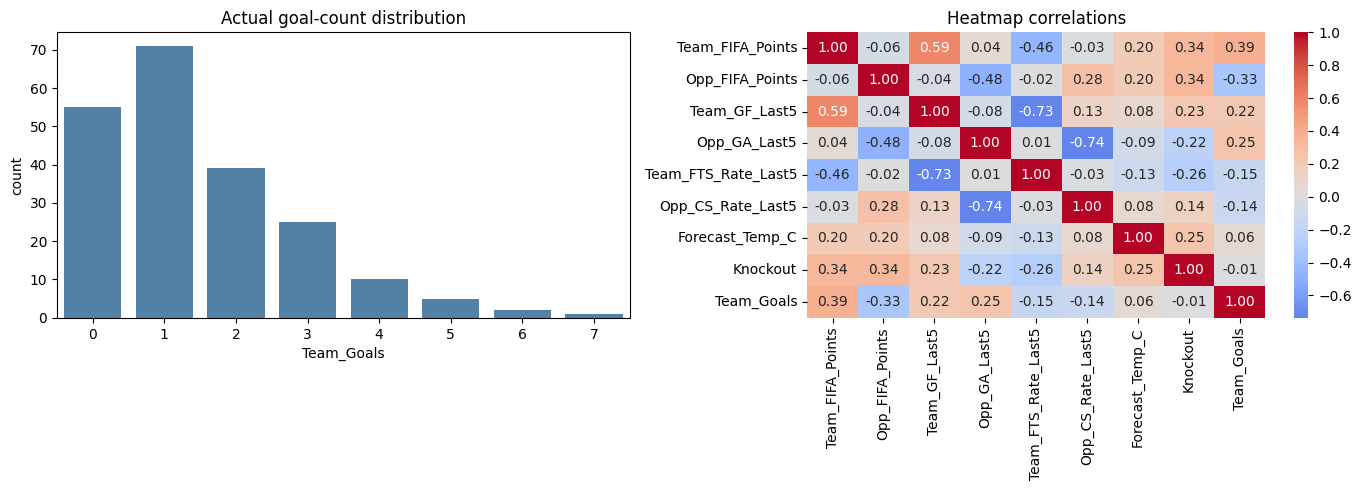

Correlations with Team_Goals:
Team_FIFA_Points       0.385
Opp_GA_Last5           0.247
Team_GF_Last5          0.222
Forecast_Temp_C        0.056
Knockout              -0.013
Opp_CS_Rate_Last5     -0.142
Team_FTS_Rate_Last5   -0.154
Opp_FIFA_Points       -0.334
Name: Team_Goals, dtype: float64


In [90]:
display(df[features+[target]].describe().T.round(3))

fig,axes=plt.subplots(1,2,figsize=(14,5))
sns.countplot(x=df[target],ax=axes[0],color="steelblue")
axes[0].set_title("Actual goal-count distribution")
corr=df[features+[target]].corr()
sns.heatmap(corr,annot=True,fmt=".2f",cmap="coolwarm",center=0,ax=axes[1],annot_kws={"size":10})
axes[1].set_title("Heatmap correlations")
plt.tight_layout();plt.show()
print("Correlations with Team_Goals:")
print(corr[target].drop(target).sort_values(ascending=False).round(3))

## 3. Random 80/20 train-test split
The data is randomly divided into train data - 80% (Used for implementing the multiple linear regression model) and test data - 20% (Used to test how good the model predicts goals for unseen matches)

In [91]:
X = df[features].copy()
y = df[target].copy()
train_idx, test_idx = train_test_split(
    np.arange(len(df)), test_size=0.20, random_state=42, shuffle=True
)
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
print("Testing data: ", len(X_test))
print("Training data: ", len(X_train))


Testing data:  42
Training data:  166


## 4. Building Models for predicting the Team_Goals

Building Linear Regression Model for predicting the team_goals. Additionally, checking other models like Yeo-Johnson + Linear Regression, Gradient Boosting, Random Forest and Poisson


,Model,Mean CV RMSE,CV RMSE SD,Mean CV MAE
1,Yeo-Johnson + Linear Regression,1.2720,0.1130,0.9723
0,Original Linear Regression,1.2805,0.1317,0.9828
3,Gradient Boosting,1.2848,0.1523,1.0181
2,Random Forest,1.2990,0.1926,1.0051
4,Poisson,1.3058,0.1525,0.9978


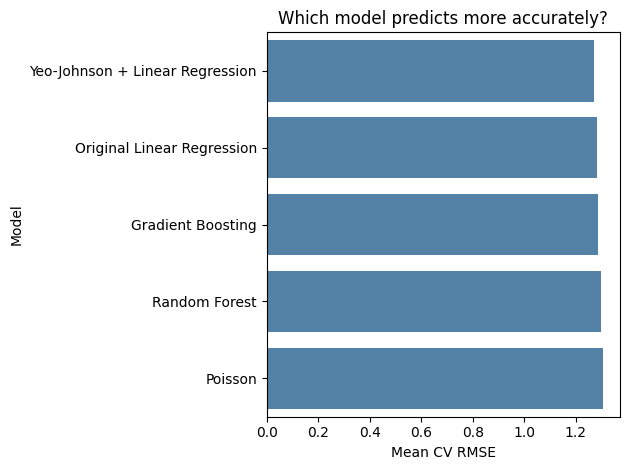

Selected model considering Cross Validation:  Yeo-Johnson + Linear Regression


In [92]:
#Implementing models
models={
 "Original Linear Regression":LinearRegression(),

 "Yeo-Johnson + Linear Regression": Pipeline([
        ("power", PowerTransformer(method="yeo-johnson")),
        ("regression", LinearRegression())
    ]),

 "Random Forest":RandomForestRegressor(
     n_estimators=200,
     min_samples_leaf=3,
     random_state=42),

 "Gradient Boosting":GradientBoostingRegressor(
     n_estimators=100,
     learning_rate=.05,
     max_depth=2,
     random_state=42),

 "Poisson":Pipeline([
     ("scale",StandardScaler()),
     ("regression",PoissonRegressor(alpha=.1,max_iter=2000))
  ])
}

#Creating five-fold cross-validation
cross_validation = KFold(n_splits = 5, shuffle = True, random_state = 42)
cross_validation_rows=[]

for i,model in models.items():
    scores=cross_validate(model,X_train,y_train,cv=cross_validation,
        scoring={"rmse":"neg_root_mean_squared_error","mae":"neg_mean_absolute_error"})
    fold_rmse=-scores["test_rmse"]
    cross_validation_rows.append({"Model":i,"Mean CV RMSE":fold_rmse.mean(),"CV RMSE SD":fold_rmse.std(),
                    "Mean CV MAE":(-scores["test_mae"]).mean()})


cross_validation_results=pd.DataFrame(cross_validation_rows).sort_values("Mean CV RMSE")
display(cross_validation_results.round(4))
ax=sns.barplot(data=cross_validation_results,x="Mean CV RMSE",y="Model",color="steelblue")
ax.set_title("Which model predicts more accurately?")
plt.tight_layout();plt.show()
selected_name=cross_validation_results.iloc[0]["Model"]
print("Selected model considering Cross Validation: ",selected_name)

## 5. Final Evaluation
Evaluating the trained regression model on the 20% test rows to predict team goals for FIFA World Cup 2026 to check whether the model will do accurate predictions on unseen football matches.

In [93]:
test_rows=[]; predictions={}; fitted={}

for i,model in models.items():
    trained=clone(model).fit(X_train,y_train)
    prediction=trained.predict(X_test)
    fitted[i]=trained
    predictions[i]=prediction
    mse=mean_squared_error(y_test,prediction)
    test_rows.append({"Model":i,"MAE":mean_absolute_error(y_test,prediction),
                      "MSE":mse,"RMSE":np.sqrt(mse),"R2":r2_score(y_test,prediction)})

test_ouput=pd.DataFrame(test_rows).sort_values("RMSE")
display(test_ouput.round(4))

,Model,MAE,MSE,RMSE,R2
4,Poisson,0.7944,1.2834,1.1329,0.3436
1,Yeo-Johnson + Linear Regression,0.8503,1.4047,1.1852,0.2816
0,Original Linear Regression,0.8493,1.4189,1.1912,0.2743
3,Gradient Boosting,0.8892,1.4327,1.1970,0.2672
2,Random Forest,0.9495,1.6204,1.2729,0.1712



## 6. Goals Prediction, error and residual behaviour
Checking how good the  selected regression model (Yeo-Johnson + Linear Regression as the best-performing model - Selected with cross validation) predicts goals and in which area it makes mistakes.


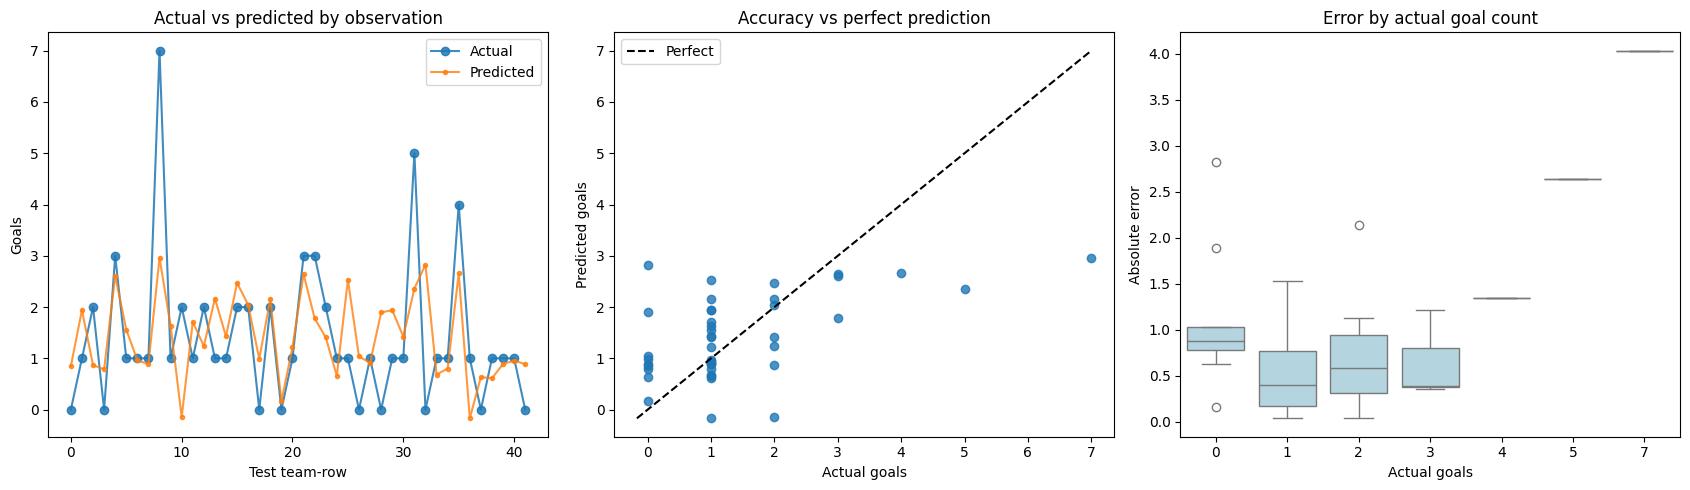

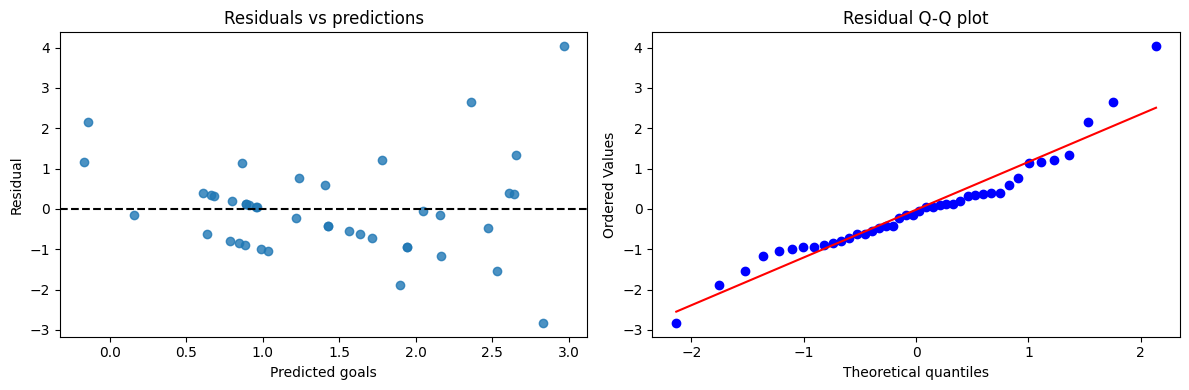

Shapiro-Wilk residual p-value: 0.0184


In [94]:
pred=predictions[selected_name]
actual=y_test.to_numpy()
residuals=actual-pred

fig,axes=plt.subplots(1,3,figsize=(17,5))
axes[0].plot(actual,"o-",label="Actual",alpha=.85)
axes[0].plot(pred,".-",label="Predicted",alpha=.8)

axes[0].set(xlabel="Test team-row",ylabel="Goals",title="Actual vs predicted by observation")
axes[0].legend()

axes[1].scatter(actual,pred,alpha=.8)
limits=[min(actual.min(),pred.min()),max(actual.max(),pred.max())]
axes[1].plot(limits,limits,"k--",label="Perfect")
axes[1].set(xlabel="Actual goals",ylabel="Predicted goals",title="Accuracy vs perfect prediction")
axes[1].legend()

sns.boxplot(x=actual,y=np.abs(residuals),ax=axes[2],color="lightblue")
axes[2].set(xlabel="Actual goals",ylabel="Absolute error",title="Error by actual goal count")
plt.tight_layout();plt.show()

fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].scatter(pred,residuals,alpha=.8);axes[0].axhline(0,ls="--",c="black")
axes[0].set(xlabel="Predicted goals",ylabel="Residual",title="Residuals vs predictions")
probplot(residuals,dist="norm",plot=axes[1]);axes[1].set_title("Residual Q-Q plot")
plt.tight_layout();plt.show()

print("Shapiro-Wilk residual p-value:",round(shapiro(residuals).pvalue,4))

## 7. Predictor importance and collinearity


Training out-of-fold RMSE: 1.277


,Feature,MAE Increase,SD
0,Team_FIFA_Points,0.247,0.028
3,Opp_GA_Last5,0.094,0.024
1,Opp_FIFA_Points,0.071,0.018
5,Opp_CS_Rate_Last5,0.040,0.010
7,Knockout,-0.000,0.001
6,Forecast_Temp_C,-0.001,0.002
4,Team_FTS_Rate_Last5,-0.001,0.002
2,Team_GF_Last5,-0.005,0.004


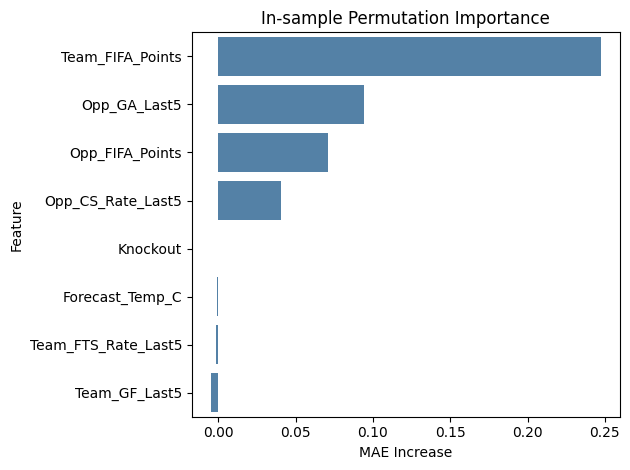

,Feature,VIF
2,Team_GF_Last5,3.08
3,Opp_GA_Last5,2.72
4,Team_FTS_Rate_Last5,2.37
5,Opp_CS_Rate_Last5,2.35
0,Team_FIFA_Points,1.85
1,Opp_FIFA_Points,1.47
7,Knockout,1.43
6,Forecast_Temp_C,1.16


In [95]:

from sklearn.model_selection import cross_val_predict
from sklearn.inspection import permutation_importance
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

# 1. 5fold cross-validation predictions
cv_pred = cross_val_predict(
    models[selected_name], X_train, y_train, cv=cross_validation
)
print("Training out-of-fold RMSE:",
      round(np.sqrt(mean_squared_error(y_train, cv_pred)), 3))


# 2. Permutation importance on training data
perm = permutation_importance(
    fitted[selected_name], X_train, y_train,
    n_repeats=20, random_state=42,
    scoring="neg_mean_absolute_error"
)

importance = pd.DataFrame({
    "Feature": features,
    "MAE Increase": perm.importances_mean,
    "SD": perm.importances_std
}).sort_values("MAE Increase", ascending=False)

display(importance.round(3))

sns.barplot(
    data=importance, x="MAE Increase",
    y="Feature", color="steelblue"
)

plt.title("In-sample Permutation Importance")
plt.tight_layout()
plt.show()


# 3. Variance Inflation Factor (VIF)
X_vif = sm.add_constant(X_train)

vif = pd.DataFrame({
    "Feature": features,
    "VIF": [
        variance_inflation_factor(X_vif.values, i + 1)
        for i in range(len(features))
    ]
})

display(vif.sort_values("VIF", ascending=False).round(2))


## 8. Prediction Option.
Option to allow user to enter values of explanatory vairables and predict goals

In [96]:
# Enter details for a new match
new_match = pd.DataFrame({
    "Team_FIFA_Points": [1750],
    "Opp_FIFA_Points": [1600],
    "Team_GF_Last5": [9],
    "Opp_GA_Last5": [7],
    "Team_FTS_Rate_Last5": [0.2],
    "Opp_CS_Rate_Last5": [0.4],
    "Forecast_Temp_C": [29],
    "Knockout": [1]
})

# Select the best model
best_model = models[selected_name]

# Train the model
best_model.fit(X_train, y_train)

# Predict goals
predicted_goals = best_model.predict(new_match)[0]

# Display prediction
print("Predicted goals:", round(max(0, predicted_goals), 2))
print("Rounded goals:", round(max(0, predicted_goals)))

Predicted goals: 2.99
Rounded goals: 3
